<a href="https://colab.research.google.com/github/conganh1982006-dotcom/SE-ROCKET-SIMULATION/blob/main/numerical_no_drag_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
h = 0.5 #step
t = np.arange(0, 2 + h, h)
Y = np.zeros(len(t)) #create array (similar to Y[]={0} in C)
m = np.zeros(len(t))
v_improve = np.zeros(len(t)) #huen
v_rk = np.zeros(len(t)) #rk4

m[0] = 1
Y[0] = 0 #intial value
ve=500
me=0.2
g=9.81
print(t)

[0.  0.5 1.  1.5 2. ]


In [ ]:
v_exact = ve * np.log(m[0] / (m[0] - me * t)) - g * t #exact solution from
for i in range(len(t) - 1):
    m[i+1] = m[i] - 0.2 * h
    Y[i + 1] = Y[i] + h * ((ve * me) / m[i] - g)  #euler method
    y1 = ((ve * me) / m[i] - g)
    y2 = ((ve * me) / m[i+1] - g)
    v_improve[i+1] = Y[i] + h/2 * (y1 + y2) #improved euler method
print(v_exact)
print(Y)
print(v_improve)
print(v_rk)

[  0.          47.77525783 101.76177566 163.62247197 235.79281188]
[  0.          45.095       95.74555556 153.34055556 219.86412698]
[  0.          47.87277778  99.21777778 157.80484127 225.81650794]
[  0.          12.44809896  82.09390336 160.51430266 249.97140832]


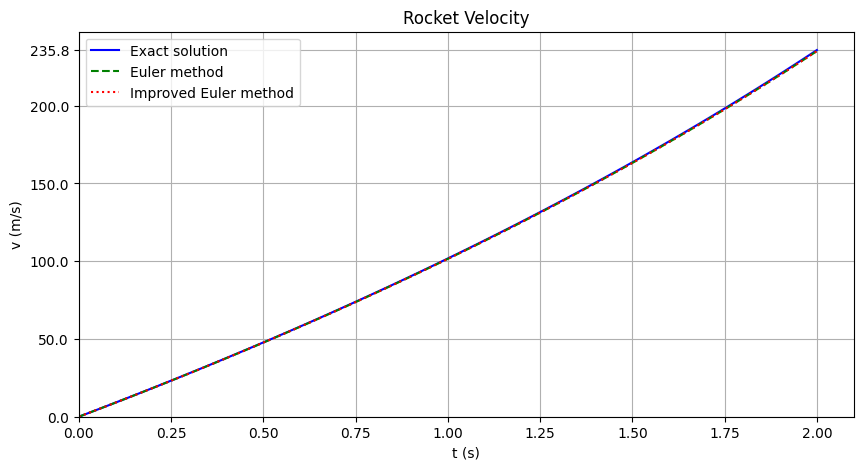

In [ ]:
plt.subplots(figsize=(10,5))
plt.plot(t, v_exact, label='Exact solution', color ='blue')
plt.plot(t, Y, label='Euler method', linestyle='--', color='green')
plt.plot(t, v_improve, label ='Improved Euler method', linestyle='dotted', color='red')

#max value
max_y = max(np.max(Y), np.max(v_exact), np.max(v_improve))
ticks = [t for t in plt.yticks()[0] if t < max_y]
ticks.append(max_y)
plt.yticks(ticks)

plt.ylim(bottom=0)
plt.xlim(left=0)

plt.title('Rocket Velocity')
plt.xlabel('t (s)')
plt.ylabel('v (m/s)')
plt.grid(True)
plt.legend()
plt.show()

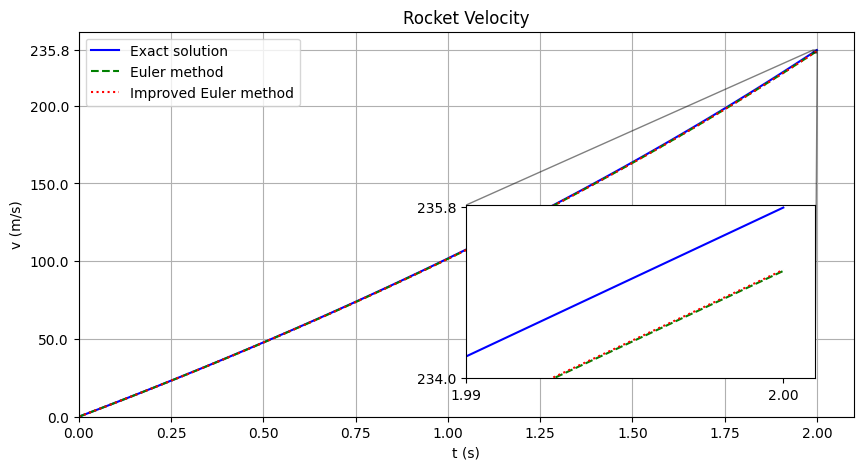

In [ ]:

#zoom in
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(t, v_exact, label="Exact solution", color="blue")
ax.plot(t, Y, label="Euler method", linestyle="--", color="green")
ax.plot(t, v_improve, label="Improved Euler method", linestyle=":", color="red")
x1, x2, y1, y2 = 1.995, 2.001, 234, 235.82
axins = ax.inset_axes([0.5, 0.1, 0.45, 0.45], xlim=(x1, x2), ylim=(y1, y2))
max_y = max(np.max(Y), np.max(v_exact), np.max(v_improve))
ticks = [t for t in plt.yticks()[0] if t < max_y]
ticks.append(max_y)
plt.yticks(ticks)

plt.ylim(bottom=0)
plt.xlim(left=0)

axins.plot(t, v_exact, label='Exact solution', color ='blue')
axins.plot(t, Y, label='Euler method', linestyle='--', color='green')
axins.plot(t, v_improve, label ='Improved Euler method', linestyle='dotted', color='red')
axins.set_xticks([1.99, 2.0])
axins.set_yticks([234, 235.8])

ax.indicate_inset_zoom(axins, edgecolor="black")


plt.title('Rocket Velocity')
plt.xlabel('t (s)')
plt.ylabel('v (m/s)')
plt.grid(True)
plt.legend()
plt.show()